# HÄLSOSTUDIEANALYS - Del 1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/health_study_dataset.csv")

print(df.head())
print(df.info())
print(df.describe())

## Beskrivande analys

In [10]:
summary = df[[
    "age",
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]].agg(["mean", "median", "min", "max"])

summary

,age,height,weight,systolic_bp,cholesterol
mean,49.42625,171.84925,73.413,149.178625,4.92915
median,50.00000,171.35000,73.200,149.400000,4.97000
min,18.00000,144.40000,33.700,106.800000,2.50000
max,90.00000,200.40000,114.400,185.900000,7.88000


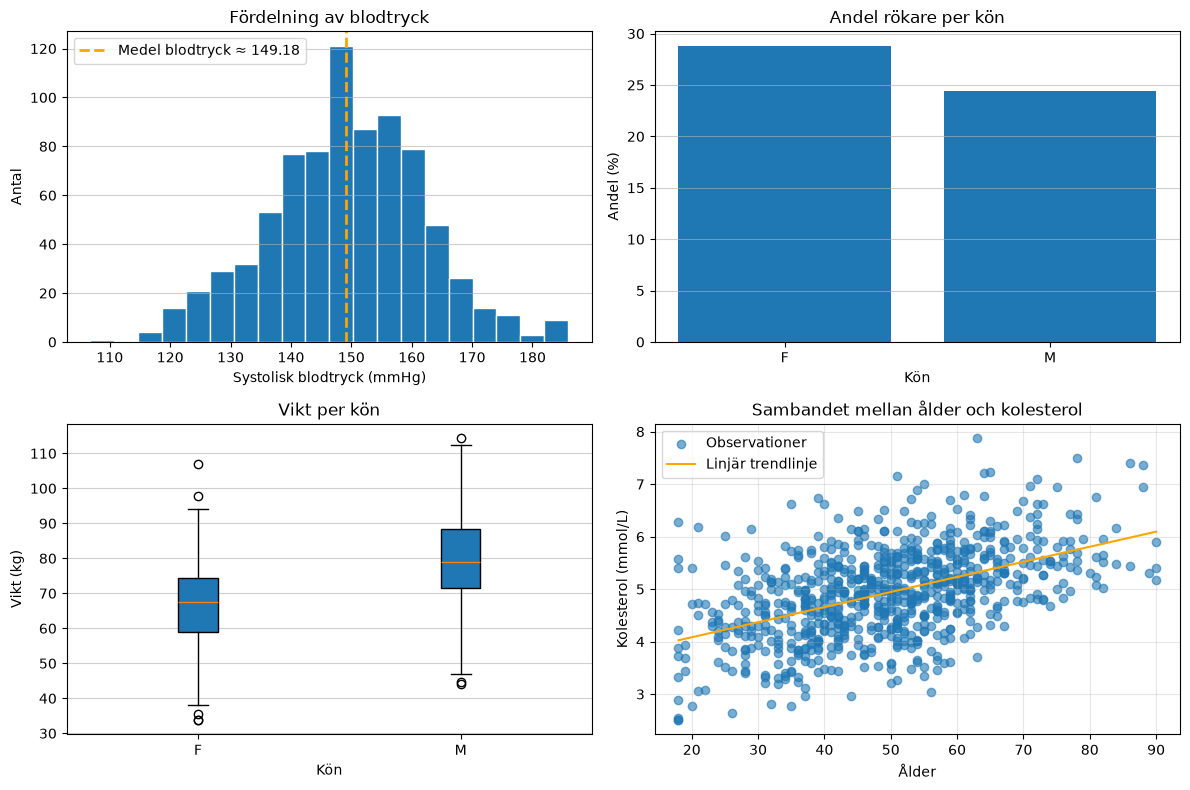

In [73]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

mean_bp = summary.loc["mean", "systolic_bp"]
axes[0, 0].hist(df.systolic_bp, bins=20, edgecolor="white")
axes[0, 0].set(title="Fördelning av blodtryck", xlabel="Systolisk blodtryck (mmHg)", ylabel="Antal")
axes[0, 0].axvline(mean_bp, ls="--", color="orange", lw=2, label=f"Medel blodtryck ≈ {mean_bp:.2f}")
axes[0, 0].grid(True, axis="y", alpha=0.6)
axes[0, 0].legend()

smokers_per_sex = (
    df.groupby("sex")["smoker"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
axes[0, 1].bar(smokers_per_sex.index, smokers_per_sex.values)
axes[0, 1].set(title="Andel rökare per kön", xlabel="Kön", ylabel="Andel (%)")
axes[0, 1].grid(True, axis="y", alpha=0.6)

female_weight = df.loc[df["sex"] == "F", "weight"]
male_weight = df.loc[df["sex"] == "M", "weight"]

axes[1, 0].boxplot(
    [female_weight, male_weight],
    tick_labels=["F", "M"],
    patch_artist=True
)
axes[1, 0].set(title="Vikt per kön", xlabel="Kön", ylabel="Vikt (kg)")
axes[1, 0].grid(True, axis="y", alpha=0.6)

x = df["age"]
y = df["cholesterol"]
k, m = np.polyfit(x, y, 1)
ix = np.argsort(x)
axes[1, 1].scatter(x, y, alpha=0.6, label="Observationer")
axes[1, 1].set(title="Sambandet mellan ålder och kolesterol", xlabel="Ålder", ylabel="Kolesterol (mmol/L)")
axes[1, 1].plot(x[ix], (k*x + m)[ix], color="orange", label=f"Linjär trendlinje")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Simulering kopplad till case

In [76]:
np.random.seed(42)

disease_rate = df["disease"].mean()

print("Andel sjukdom av observationerna:", disease_rate * 100, "%")

Andel sjukdom av observationerna: 5.875 %


# Konfidensintervall normalapproximation

In [101]:
systolic_bp = df["systolic_bp"].dropna()

mean_bp = systolic_bp.mean()
sd = systolic_bp.std(ddof=1)
n = len(systolic_bp)

print("Medelvärde för blodtryck:", round(mean_bp, 2))
print("Standardavvikelse:", round(sd, 2))
print("Antal observationer:", n)
print()

se = sd / np.sqrt(n)
z = 1.96
half_width = z * se
lo, hi = mean_bp - half_width, mean_bp + half_width

print("Standarderror:", round(se, 3))
print(f"95%-CI: ({lo:.3f}, {hi:.3f})")

Medelvärde för blodtryck: 149.18
Standardavvikelse: 12.79
Antal observationer: 800

Standarderror: 0.452
95%-CI: (148.292, 150.065)


# Konfidensintervall bootstrap

In [102]:
systolic_bp = df["systolic_bp"].dropna().to_numpy()
confidence = 0.95
B = 1000

n = len(systolic_bp)
boot_means = np.empty(B)
for b in range(B):
    boot_sample = np.random.choice(systolic_bp, size=n, replace=True)
    boot_means[b] = np.mean(boot_sample)

alpha = (1 - confidence) / 2
blo, bhi = np.percentile(boot_means, [100 * alpha, 100 * (1 - alpha)])

print(f"Konfidensintervall med bootstrap metoden: ({blo:.3f}, {bhi:.3f})")
print("\nSkillnader i gränserna mellan metoderna (normalapproximation och bootstrap):")
print(f"Skillnad undre: {lo - blo:.3f}, skillnad högre: {hi - bhi:.3f}")

Konfidensintervall med bootstrap metoden: (148.246, 150.058)

Skillnader i gränserna mellan metoderna (normalapproximation och bootstrap):
Skillnad undre: 0.046, skillnad högre: 0.007


Skillnaderna i konfidensintervallen mellan normalapproximationen och bootstrapmetoden är väldigt små. Detta tyder på att datan är relativt normalfördelad och att urvalet är tillräckligt stort för att normalapproximationen ska fungera.